# Prediction Intervals and Calibration

## Imports

In [1]:
import os
import sys
import time
import pickle
import itertools
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sys.path.append('../src')
from zoo import TASKS, FAMILY, META, SEED, reg_models, clf_models, make_pipeline, grid_prefix, load_task, make_folds

warnings.filterwarnings('ignore')
sns.set_theme(style='ticks', context='notebook')

import math
import joblib
from scipy.stats import spearmanr, norm
from sklearn.base import clone
from sklearn.model_selection import GroupKFold

## Settings

In [2]:
RESULTS = '../results'
LEVELS = np.round(np.arange(0.50, 0.96, 0.05), 2)
zoo = pd.concat([pd.read_csv(f'{RESULTS}/{t}__zoo_results.csv') for t in TASKS], ignore_index=True)

## Helper Functions

In [3]:
def conformal_quantile(scores, level):
    n = len(scores)
    k = min(int(math.ceil((n + 1) * level)), n)
    return np.sort(scores)[k - 1]


def clipped_width(pred, half):
    # width of the interval after the lower bound is cut at zero (loads and strengths cannot be negative)
    return np.maximum((pred + half) - np.maximum(pred - half, 0), 0)

## Regression Tasks: Intervals

In [4]:
intervals = {}
for task in [t for t in TASKS if not t.endswith('FailureMode')]:
    df, X, y, groups, is_clf, target = load_task(task)
    predictions = pickle.load(open(f'{RESULTS}/{task}__predictions.pkl', 'rb'))
    R = zoo[zoo['File'] == task].set_index('Model')
    p0 = predictions[R.index[0]]
    train, test = p0['train_idx'], p0['test_idx']
    X_train, X_test = X.iloc[train], X.iloc[test]
    y_train, y_test = y[train], y[test]

    best = R['Test_r2'].idxmax()
    oof = predictions[best]['oof']
    pred_test = predictions[best]['pred_test']
    residuals = np.abs(y_train - oof)

    # local scale: size of the prediction, with a floor
    floor = 0.05 * float(np.median(np.abs(y_train))) + 1e-9
    scale_oof = np.maximum(np.abs(oof), floor)
    scale_test = np.maximum(np.abs(pred_test), floor)

    # native interval of Gaussian-process regression
    gpr = joblib.load(f'{RESULTS}/models/{task}__GPR.joblib')
    mu_test, sd_test = gpr.predict(X_test, return_std=True)
    n_splits = min(5, len(set(groups[train])))
    folds = list(GroupKFold(n_splits).split(X_train, y_train, groups[train]))
    mu_oof, sd_oof = np.zeros(len(train)), np.zeros(len(train))
    for a, b in folds:
        m = clone(gpr).fit(X_train.iloc[a], y_train[a])
        mu_oof[b], sd_oof[b] = m.predict(X_train.iloc[b], return_std=True)

    out = {}
    for level in LEVELS:
        z = norm.ppf((1 + level) / 2)
        # random-split test part
        q = conformal_quantile(residuals, level)
        lo, hi = np.maximum(pred_test - q, 0), pred_test + q
        q_rel = conformal_quantile(residuals / scale_oof, level)
        lo_rel, hi_rel = np.maximum(pred_test - q_rel * scale_test, 0), pred_test + q_rel * scale_test
        lo_gp, hi_gp = np.maximum(mu_test - z * sd_test, 0), mu_test + z * sd_test
        # records of studies not seen in training: calibrated on the residuals of the other folds
        cover = dict(abs=[], rel=[], gpr=[])
        width = dict(abs=[], rel=[], gpr=[])
        for a, b in folds:
            qa = conformal_quantile(residuals[a], level)
            qr = conformal_quantile(residuals[a] / scale_oof[a], level)
            cover['abs'] += list(np.abs(y_train[b] - oof[b]) <= qa)
            width['abs'] += list(clipped_width(oof[b], qa))
            cover['rel'] += list(np.abs(y_train[b] - oof[b]) <= qr * scale_oof[b])
            width['rel'] += list(clipped_width(oof[b], qr * scale_oof[b]))
            cover['gpr'] += list(np.abs(y_train[b] - mu_oof[b]) <= z * sd_oof[b])
            width['gpr'] += list(clipped_width(mu_oof[b], z * sd_oof[b]))
        out[level] = dict(
            test_cov=dict(abs=float(np.mean((y_test >= lo) & (y_test <= hi))), rel=float(np.mean((y_test >= lo_rel) & (y_test <= hi_rel))),
                          gpr=float(np.mean((y_test >= lo_gp) & (y_test <= hi_gp)))),
            test_w=dict(abs=float(np.mean(hi - lo)), rel=float(np.mean(hi_rel - lo_rel)), gpr=float(np.mean(hi_gp - lo_gp))),
            unseen_cov={k: float(np.mean(v)) for k, v in cover.items()},
            unseen_w={k: float(np.mean(v)) for k, v in width.items()})
    intervals[task] = dict(best=best, levels=LEVELS, U=out, y_te=y_test, pte=pred_test, s_te=scale_test,
                           mu_te=mu_test, sd_te=sd_test, z9=float(norm.ppf(0.95)),
                           q9=float(conformal_quantile(residuals, 0.9)), qa9=float(conformal_quantile(residuals / scale_oof, 0.9)),
                           rho_rel=float(spearmanr(scale_test, np.abs(y_test - pred_test))[0]),
                           rho_gpr=float(spearmanr(sd_test, np.abs(y_test - mu_test))[0]))
    print(task, best, 'done')

CFRP_CFRP__MaxLoad LGBM done


Composite_Composite__MaxLoad GB done


CFRP_CFRP__LSS GB done


Composite_Composite__LSS RF done


## 90% Intervals

In [5]:
rows = []
for task, r in intervals.items():
    u = r['U'][0.9]
    for kind, label in [('abs', 'Conformal, constant width'), ('rel', 'Conformal, scaled'), ('gpr', 'Gaussian process')]:
        rows.append(dict(Task=task, Interval=label,
                         Coverage_random=round(100 * u['test_cov'][kind], 1), Width_random=round(u['test_w'][kind], 2),
                         Coverage_unseen=round(100 * u['unseen_cov'][kind], 1), Width_unseen=round(u['unseen_w'][kind], 2)))
interval_table = pd.DataFrame(rows)
interval_table

,Task,Interval,Coverage_random,Width_random,Coverage_unseen,Width_unseen
0,CFRP_CFRP__MaxLoad,"Conformal, constant width",98.1,45.75,79.2,45.39
1,CFRP_CFRP__MaxLoad,"Conformal, scaled",98.7,43.72,86.9,57.50
2,CFRP_CFRP__MaxLoad,Gaussian process,91.6,12.17,89.4,64.75
3,Composite_Composite__MaxLoad,"Conformal, constant width",100.0,28.82,88.1,30.26
4,Composite_Composite__MaxLoad,"Conformal, scaled",99.5,28.61,83.4,37.01
5,Composite_Composite__MaxLoad,Gaussian process,94.3,13.99,96.1,54.69
6,CFRP_CFRP__LSS,"Conformal, constant width",100.0,25.35,89.4,27.44
7,CFRP_CFRP__LSS,"Conformal, scaled",99.3,28.23,89.4,29.16
8,CFRP_CFRP__LSS,Gaussian process,95.6,12.06,80.6,28.58
9,Composite_Composite__LSS,"Conformal, constant width",99.0,26.52,84.6,27.79


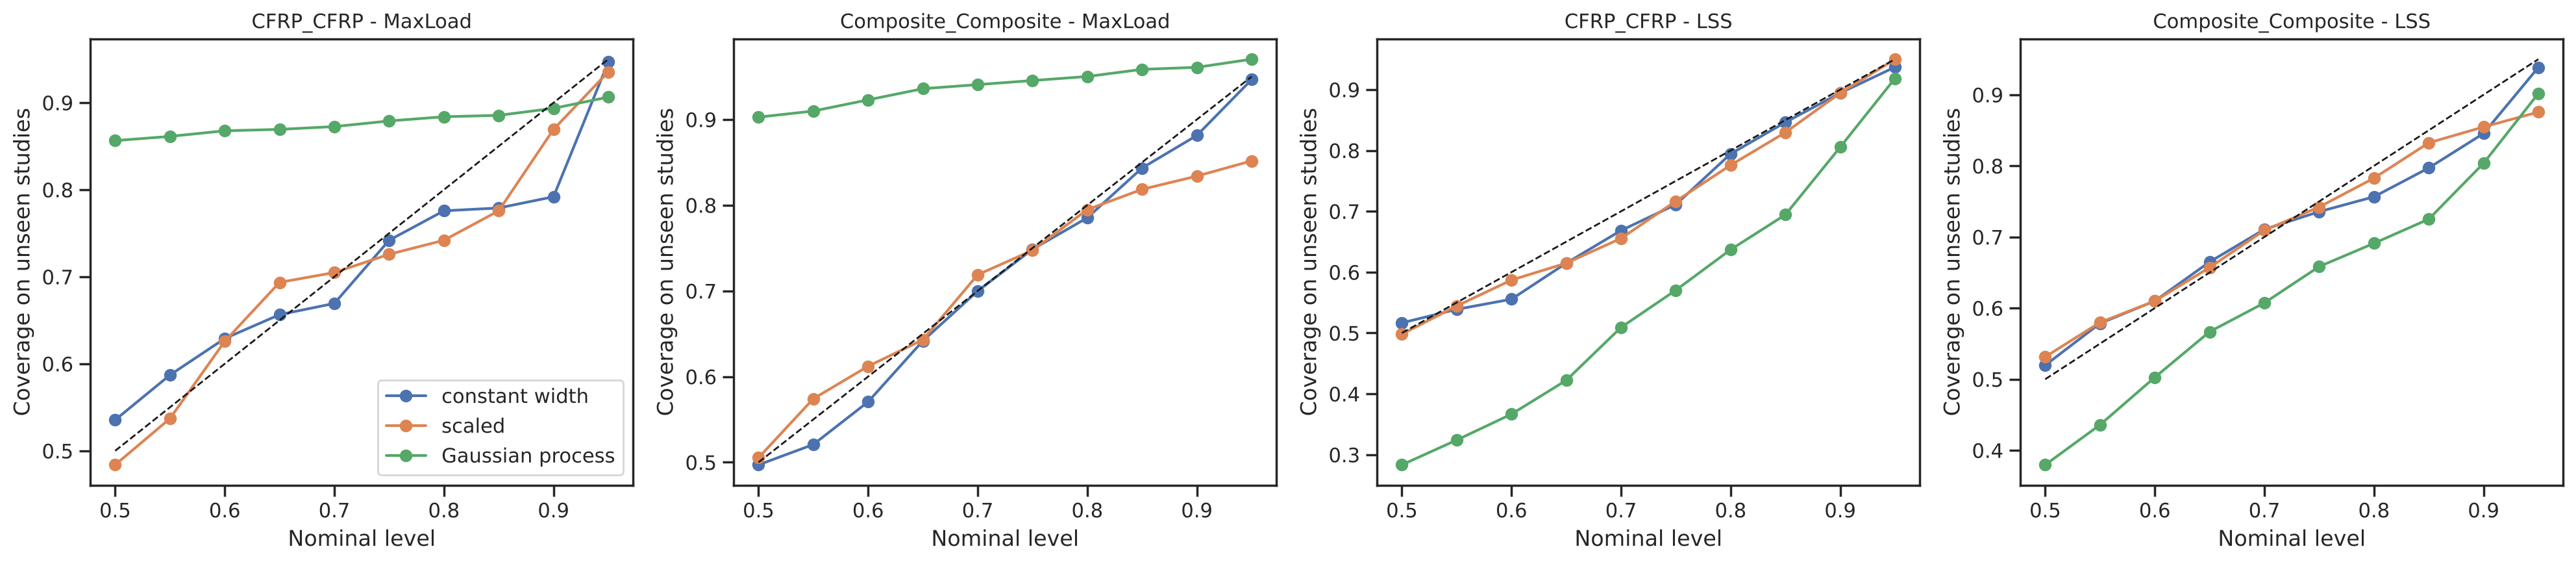

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (task, r) in zip(axes, intervals.items()):
    levels = r['levels']
    for kind, label in [('abs', 'constant width'), ('rel', 'scaled'), ('gpr', 'Gaussian process')]:
        ax.plot(levels, [r['U'][l]['unseen_cov'][kind] for l in levels], marker='o', label=label)
    ax.plot([0.5, 0.95], [0.5, 0.95], 'k--', lw=1)
    ax.set_title(task.replace('__', ' - '), fontsize=11)
    ax.set_xlabel('Nominal level'); ax.set_ylabel('Coverage on unseen studies')
axes[0].legend()
plt.tight_layout()
plt.show()

## Classification Tasks: Reliability

In [7]:
reliability = {}
for task in [t for t in TASKS if t.endswith('FailureMode')]:
    df, X, y, groups, is_clf, target = load_task(task)
    predictions = pickle.load(open(f'{RESULTS}/{task}__predictions.pkl', 'rb'))
    y_test = predictions[zoo[zoo['File'] == task]['Model'].iloc[0]]['y_test']
    rel = {}
    for name in zoo[zoo['File'] == task]['Model']:
        proba = predictions[name]['proba']
        if proba is None:
            continue
        model = joblib.load(f'{RESULTS}/models/{task}__{name}.joblib')
        pred = model.classes_[proba.argmax(1)]
        conf = proba.max(1)
        correct = (pred == y_test).astype(float)
        bins = np.linspace(0, 1, 6)
        bin_id = np.clip(np.digitize(conf, bins) - 1, 0, 4)
        bx = [conf[bin_id == k].mean() if (bin_id == k).any() else np.nan for k in range(5)]
        by = [correct[bin_id == k].mean() if (bin_id == k).any() else np.nan for k in range(5)]
        bn = [(bin_id == k).sum() for k in range(5)]
        ece = float(sum(n * abs(a - b) for n, a, b in zip(bn, bx, by) if n > 0) / len(conf))
        order = np.argsort(-conf)
        retention = np.cumsum(correct[order]) / np.arange(1, len(order) + 1)
        rel[name] = dict(ece=ece, bx=bx, by=by, bn=bn, retention=retention, acc=float(correct.mean()), conf_mean=float(conf.mean()))
    reliability[task] = rel
pd.DataFrame({t: {m: v['ece'] for m, v in r.items()} for t, r in reliability.items()}).round(3)

,CFRP_CFRP__FailureMode,Composite_Composite__FailureMode
LogReg-L2,0.066,0.080
LogReg-L1,0.042,0.046
SVC,0.037,0.057
MLP,0.135,0.106
DT,0.028,0.070
RF,0.077,0.058
ET,0.060,0.076
GB,0.012,0.043
XGB,0.027,0.029
LGBM,0.016,0.057


## Save

In [8]:
with open(f'{RESULTS}/intervals.pkl', 'wb') as fh:
    pickle.dump(intervals, fh)
with open(f'{RESULTS}/reliability.pkl', 'wb') as fh:
    pickle.dump(reliability, fh)
interval_table.to_csv(f'{RESULTS}/intervals_90.csv', index=False)